# Telco -- SMOTE Augmentation for Churn Classification

Apply **SMOTE** (Synthetic Minority Over-sampling Technique) to balance the training set up to **60/40** (non-churn / churn), then compare results against the unaugmented semi-supervised baseline from `telco_semi_supervised.ipynb`.

**Rule:** synthetic samples are only used in training -- the stop (threshold) set and the test set always contain real customers only.

## 1. Setup

In [51]:
from __future__ import annotations
import sys
from pathlib import Path

_w4_root = Path().resolve()
if str(_w4_root) not in sys.path:
    sys.path.insert(0, str(_w4_root))

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, precision_recall_curve,
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

from constants import SEED, CHECKPOINTS_DIR, RUNS_DIR
from autoencoder.data_loader  import load_telco_data, filter_normal
from train.train_ae import load_checkpoint, set_seed

SMOTE_DIR   = RUNS_DIR / 'smote'
SMOTE_FIG   = SMOTE_DIR / 'figures'
SMOTE_DIR.mkdir(parents=True, exist_ok=True)
SMOTE_FIG.mkdir(parents=True, exist_ok=True)

SS_RUNS_DIR = RUNS_DIR / 'semi_supervised'

DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH       = 2048
SMOTE_RATIO = 40 / 60   # minority/majority target -> 40% churn in training

set_seed(SEED)
print('device:', DEVICE)

device: cpu


## 2. Data & AE checkpoint

In [52]:
df, y_all, _, categorical, numeric, split = load_telco_data()

ae_model, ae_cfg, prep, _, _ = load_checkpoint(CHECKPOINTS_DIR / 'ae_best.pt', DEVICE)
ae_model.eval()
print(f'AE z_dim={ae_cfg.z_dim}  |  numeric_dim={prep.numeric_dim}')

fit_idx  = split['fit']
stop_idx = split['stop']
test_idx = split['test']

df_fit  = df.iloc[fit_idx].reset_index(drop=True)
df_stop = df.iloc[stop_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

y_fit  = y_all[fit_idx]
y_stop = y_all[stop_idx]
y_test = y_all[test_idx]

x_num_fit,  x_cat_fit  = prep.transform(df_fit)
x_num_stop, x_cat_stop = prep.transform(df_stop)
x_num_test, x_cat_test = prep.transform(df_test)

print(f'fit  : {len(y_fit):>5,}  churn={y_fit.sum():>4,}  ({y_fit.mean():.2%})')
print(f'stop : {len(y_stop):>5,}  churn={y_stop.sum():>4,}  ({y_stop.mean():.2%})')
print(f'test : {len(y_test):>5,}  churn={y_test.sum():>4,}  ({y_test.mean():.2%})')

AE z_dim=16  |  numeric_dim=4
fit  : 4,930  churn=1,308  (26.53%)
stop : 1,056  churn= 280  (26.52%)
test : 1,057  churn= 281  (26.58%)


## 3. Feature helpers

In [53]:
def _batches(x_num, x_cat, batch_size, device):
    for i in range(0, len(x_num), batch_size):
        yield x_num[i:i+batch_size].to(device), x_cat[i:i+batch_size].to(device)


def extract_latent(model, x_num, x_cat, device=DEVICE, batch_size=BATCH):
    model.eval()
    parts = []
    with torch.no_grad():
        for bn, bc in _batches(x_num, x_cat, batch_size, device):
            parts.append(model.encode(bn, bc).cpu())
    return torch.cat(parts).numpy()


def recon_error(model, x_num, x_cat, device=DEVICE, batch_size=BATCH):
    model.eval()
    parts = []
    with torch.no_grad():
        for bn, bc in _batches(x_num, x_cat, batch_size, device):
            _, num_out, cat_logits = model(bn, bc)
            num_err = F.mse_loss(num_out, bn, reduction='none').sum(dim=-1)
            cat_err = torch.stack(
                [F.cross_entropy(logits, bc[:, k], reduction='none')
                 for k, logits in enumerate(cat_logits)], dim=1
            ).sum(dim=1)
            parts.append((num_err + cat_err).cpu())
    return torch.cat(parts).numpy()


def build_base(x_num, x_cat, prep):
    oh_parts = [
        F.one_hot(x_cat[:, i].long(), card).float().numpy()
        for i, card in enumerate(prep.cat_cardinalities)
    ]
    return np.hstack([x_num.numpy()] + oh_parts)


print('Extracting AE features...')
feats = {}
for name, (xn, xc) in [('fit',  (x_num_fit,  x_cat_fit)),
                        ('stop', (x_num_stop, x_cat_stop)),
                        ('test', (x_num_test, x_cat_test))]:
    feats[name] = {
        'z':    extract_latent(ae_model, xn, xc),
        'recon': recon_error(ae_model, xn, xc).reshape(-1, 1),
        'base':  build_base(xn, xc, prep),
    }
    print(f'  {name}: z{feats[name]["z"].shape}  base{feats[name]["base"].shape}')
print('Done.')

Extracting AE features...
  fit: z(4930, 16)  base(4930, 60)
  stop: z(1056, 16)  base(1056, 60)
  test: z(1057, 16)  base(1057, 60)
Done.


## 4. Feature variants

In [54]:
def build_variants(f):
    z, r, b = f['z'], f['recon'], f['base']
    return {
        'z_AE':          z,
        'z_AE + recon':  np.hstack([z, r]),
        'base only':     b,
        'base + recon':  np.hstack([b, r]),
        'base + z_AE':   np.hstack([b, z]),
        'base + z + r':  np.hstack([b, z, r]),
    }

variants = {s: build_variants(feats[s]) for s in ('fit', 'stop', 'test')}

print('Feature variants (dims):')
for name, arr in variants['fit'].items():
    print(f'  {name:<22}  {arr.shape[1]}')

Feature variants (dims):
  z_AE                    16
  z_AE + recon            17
  base only               60
  base + recon            61
  base + z_AE             76
  base + z + r            77


## 5. SMOTE -- class balance analysis

SMOTE generates synthetic minority-class (churn) samples by interpolating between real churn customers in feature space.  
Target: **40% churn** in the augmented training set.

> **Note:** SMOTE operates on the already-encoded feature vectors (standardised numerics + one-hot categoricals). One-hot dimensions may become non-binary after interpolation -- this is expected and does not affect classifier performance meaningfully.

Before SMOTE : 4,930 samples  churn=26.53%
After SMOTE  : 6,036 samples  churn=39.99%
Synthetic churn samples created: 1,106


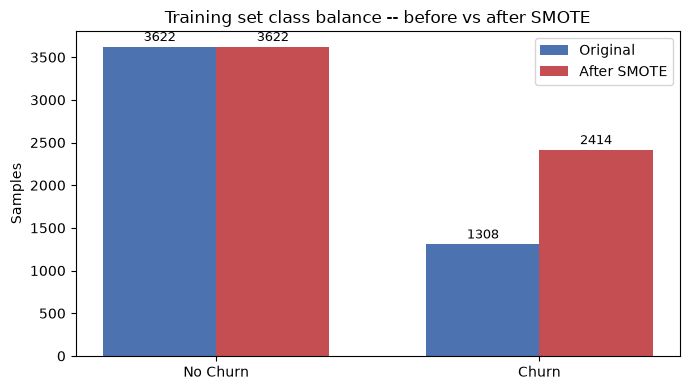

In [55]:
# Show class counts before / after SMOTE for one representative variant
_X_demo = variants['fit']['base only']
smote_demo = SMOTE(sampling_strategy=SMOTE_RATIO, random_state=SEED)
_X_aug, _y_aug = smote_demo.fit_resample(_X_demo, y_fit)

before_churn = y_fit.mean()
after_churn  = _y_aug.mean()
n_synthetic  = len(_y_aug) - len(y_fit)

print(f'Before SMOTE : {len(y_fit):>5,} samples  churn={before_churn:.2%}')
print(f'After SMOTE  : {len(_y_aug):>5,} samples  churn={after_churn:.2%}')
print(f'Synthetic churn samples created: {n_synthetic:,}')

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(2)
w = 0.35
orig_counts = np.array([(y_fit == 0).sum(), (y_fit == 1).sum()])
aug_counts  = np.array([(_y_aug == 0).sum(), (_y_aug == 1).sum()])
b1 = ax.bar(x - w/2, orig_counts, w, label='Original',     color='#4c72b0')
b2 = ax.bar(x + w/2, aug_counts,  w, label='After SMOTE',  color='#c44e52')
ax.set_xticks(x, ['No Churn', 'Churn'])
ax.set_ylabel('Samples')
ax.set_title('Training set class balance -- before vs after SMOTE')
ax.bar_label(b1, fmt='%d', padding=2, fontsize=9)
ax.bar_label(b2, fmt='%d', padding=2, fontsize=9)
ax.legend()
plt.tight_layout()
plt.savefig(SMOTE_FIG / 'smote_balance.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Evaluation utilities

In [56]:
def best_f1_threshold(y_true, y_prob):
    precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
    denom = precision[:-1] + recall[:-1]
    f1 = np.where(denom > 0, 2 * precision[:-1] * recall[:-1] / denom, 0.0)
    return float(thresholds[np.argmax(f1)])


def evaluate(y_true, y_prob, threshold, clf_name, feat_name):
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return {
        'classifier':        clf_name,
        'features':          feat_name,
        'model':             f'{clf_name}({feat_name})',
        'roc_auc':           float(roc_auc_score(y_true, y_prob)),
        'average_precision': float(average_precision_score(y_true, y_prob)),
        'threshold':         float(threshold),
        'precision_churn':   float(prec),
        'recall_churn':      float(rec),
        'f1_churn':          float(f1),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }


def run_smote_exp(clf_template, X_fit, X_stop, X_test,
                  y_fit, y_stop, y_test, clf_name, feat_name):
    smote    = SMOTE(sampling_strategy=SMOTE_RATIO, random_state=SEED)
    X_aug, y_aug = smote.fit_resample(X_fit, y_fit)

    scaler    = StandardScaler()
    X_aug_sc  = scaler.fit_transform(X_aug)
    X_stop_sc = scaler.transform(X_stop)
    X_test_sc = scaler.transform(X_test)

    clf = clone(clf_template)
    clf.fit(X_aug_sc, y_aug)

    threshold = best_f1_threshold(y_stop, clf.predict_proba(X_stop_sc)[:, 1])
    return evaluate(y_test, clf.predict_proba(X_test_sc)[:, 1], threshold, clf_name, feat_name)


SHOW = ['model', 'roc_auc', 'average_precision', 'f1_churn', 'recall_churn', 'precision_churn']
print('Utilities ready.')

Utilities ready.


## 7. Experiment -- 3 classifiers x 6 feature variants with SMOTE

Same classifiers and feature variants as `telco_semi_supervised.ipynb` Exp A, but with SMOTE-balanced training data (40% churn).  
Stop and test sets are always real data.

In [57]:
classifiers = {
    'LR':  LogisticRegression(class_weight='balanced', max_iter=1000,
                               random_state=SEED, solver='lbfgs'),
    'RF':  RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
    'XGB': XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4,
                          random_state=SEED, eval_metric='logloss', verbosity=0),
}

rows = []
for clf_name, clf_tpl in classifiers.items():
    for feat_name in variants['fit']:
        row = run_smote_exp(
            clf_tpl,
            variants['fit'][feat_name],  variants['stop'][feat_name],  variants['test'][feat_name],
            y_fit, y_stop, y_test,
            clf_name, feat_name,
        )
        rows.append(row)
        print(f"  {clf_name:4s}  {feat_name:22s}  AUC={row['roc_auc']:.4f}  "
              f"F1={row['f1_churn']:.4f}  Recall={row['recall_churn']:.4f}")

smote_results = pd.DataFrame(rows)
smote_results.to_csv(SMOTE_DIR / 'smote_results.csv', index=False)
print('\nSaved smote_results.csv')

  LR    z_AE                    AUC=0.8462  F1=0.6337  Recall=0.7295
  LR    z_AE + recon            AUC=0.8451  F1=0.6398  Recall=0.7331
  LR    base only               AUC=0.8492  F1=0.6417  Recall=0.7331
  LR    base + recon            AUC=0.8493  F1=0.6401  Recall=0.7153
  LR    base + z_AE             AUC=0.8495  F1=0.6486  Recall=0.7224
  LR    base + z + r            AUC=0.8479  F1=0.6331  Recall=0.7153
  RF    z_AE                    AUC=0.8156  F1=0.5888  Recall=0.6548
  RF    z_AE + recon            AUC=0.8113  F1=0.5809  Recall=0.6833
  RF    base only               AUC=0.8269  F1=0.6154  Recall=0.7117
  RF    base + recon            AUC=0.8254  F1=0.6087  Recall=0.7722
  RF    base + z_AE             AUC=0.8225  F1=0.5976  Recall=0.7082
  RF    base + z + r            AUC=0.8201  F1=0.6060  Recall=0.7580
  XGB   z_AE                    AUC=0.8435  F1=0.6219  Recall=0.8078
  XGB   z_AE + recon            AUC=0.8432  F1=0.6280  Recall=0.7509
  XGB   base only               AU

### 7a. AUC heatmap (SMOTE)

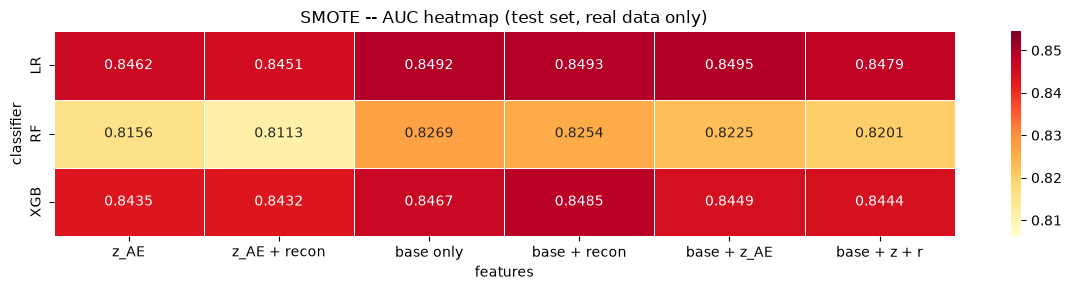


            model  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
  LR(base + z_AE)   0.8495             0.6529    0.6486        0.7224           0.5884
 LR(base + recon)   0.8493             0.6588    0.6401        0.7153           0.5793
    LR(base only)   0.8492             0.6557    0.6417        0.7331           0.5706
XGB(base + recon)   0.8485             0.6669    0.6460        0.8149           0.5350
 LR(base + z + r)   0.8479             0.6496    0.6331        0.7153           0.5678
   XGB(base only)   0.8467             0.6616    0.6558        0.7865           0.5623
         LR(z_AE)   0.8462             0.6612    0.6337        0.7295           0.5601
 LR(z_AE + recon)   0.8451             0.6594    0.6398        0.7331           0.5675
 XGB(base + z_AE)   0.8449             0.6636    0.6544        0.6940           0.6190
XGB(base + z + r)   0.8444             0.6568    0.6459        0.6655           0.6275
        XGB(z_AE)   0.8435             0.6

In [58]:
pivot = smote_results.pivot(index='classifier', columns='features', values='roc_auc')
pivot = pivot.reindex(index=list(classifiers.keys()),
                      columns=list(variants['fit'].keys()))

fig, ax = plt.subplots(figsize=(12, 3))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlOrRd',
            vmin=pivot.values.min() - 0.005,
            vmax=pivot.values.max() + 0.005,
            linewidths=0.5, ax=ax)
ax.set_title('SMOTE -- AUC heatmap (test set, real data only)')
plt.tight_layout()
plt.savefig(SMOTE_FIG / 'smote_auc_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print(smote_results[SHOW].sort_values('roc_auc', ascending=False)
      .to_string(index=False, float_format=lambda x: f'{x:.4f}'))

## 8. SMOTE vs Baseline -- direct comparison

Load the best results from `telco_semi_supervised.ipynb` (no SMOTE) and compare head-to-head on the same test set.

In [59]:
COMPARE_COLS = ['model', 'method', 'roc_auc', 'average_precision',
                'f1_churn', 'recall_churn', 'precision_churn']

best_smote = smote_results.sort_values('roc_auc', ascending=False).head(3).copy()
best_smote['method'] = 'SMOTE'

baseline_path = SS_RUNS_DIR / 'final_comparison.csv'
if baseline_path.exists():
    baseline  = pd.read_csv(baseline_path)
    best_base = baseline.sort_values('roc_auc', ascending=False).head(3).copy()
    combined  = pd.concat([best_smote[COMPARE_COLS], best_base[COMPARE_COLS]],
                           ignore_index=True).sort_values('roc_auc', ascending=False)
else:
    print('final_comparison.csv not found -- run telco_semi_supervised.ipynb first.')
    combined = best_smote[COMPARE_COLS]

combined.to_csv(SMOTE_DIR / 'smote_vs_baseline.csv', index=False)
print('=== SMOTE vs Baseline (sorted by AUC) ===')
print(combined.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

=== SMOTE vs Baseline (sorted by AUC) ===
              model               method  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
    LR(base + z_AE)                SMOTE   0.8495             0.6529    0.6486        0.7224           0.5884
      LR(base only) Exp A — best per clf   0.8494             0.6540    0.6333        0.6975           0.5799
   LR(base + recon)                SMOTE   0.8493             0.6588    0.6401        0.7153           0.5793
      LR(base only)                SMOTE   0.8492             0.6557    0.6417        0.7331           0.5706
     XGB(base only) Exp A — best per clf   0.8480             0.6668    0.6331        0.7829           0.5314
XGB_base(base only)   Exp B — XGB tuning   0.8480             0.6668    0.6331        0.7829           0.5314


### 8a. Bar chart -- AUC and F1

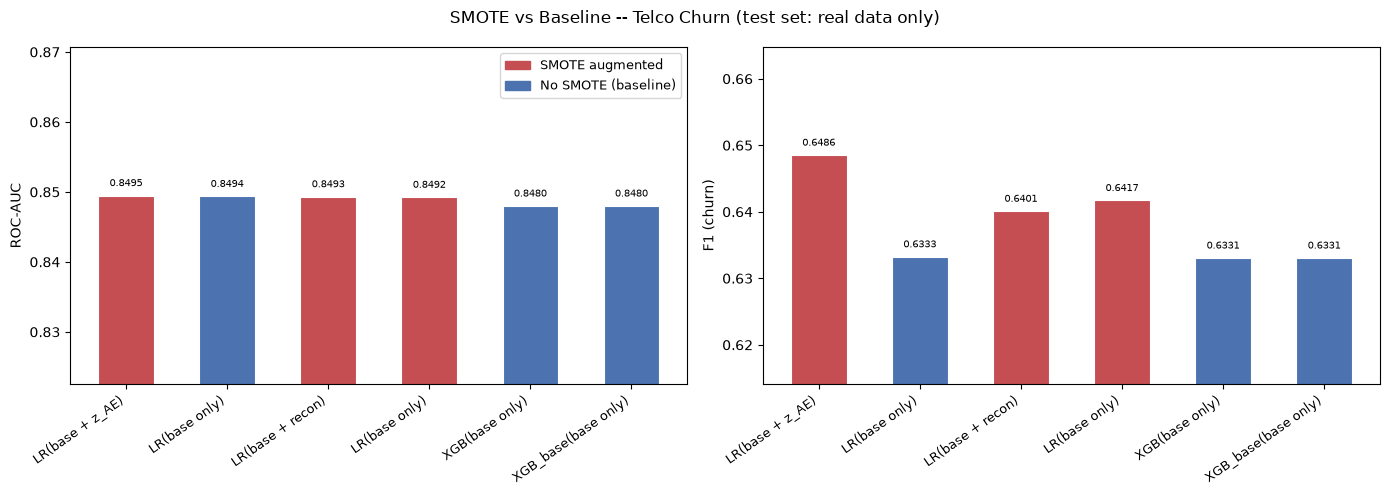

In [60]:
from matplotlib.patches import Patch

_colors = ['#c44e52' if m == 'SMOTE' else '#4c72b0' for m in combined['method']]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(combined))

for ax, metric, ylabel in [
    (axes[0], 'roc_auc',  'ROC-AUC'),
    (axes[1], 'f1_churn', 'F1 (churn)'),
]:
    bars = ax.bar(x, combined[metric], color=_colors, width=0.55,
                  edgecolor='white', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(combined['model'], rotation=35, ha='right', fontsize=9)
    ax.set_ylabel(ylabel)
    ax.set_ylim(combined[metric].min() * 0.97, combined[metric].max() * 1.025)
    for bar, val in zip(bars, combined[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
                f'{val:.4f}', ha='center', va='bottom', fontsize=7.5)

axes[0].legend(handles=[
    Patch(color='#c44e52', label='SMOTE augmented'),
    Patch(color='#4c72b0', label='No SMOTE (baseline)'),
], fontsize=9)
plt.suptitle('SMOTE vs Baseline -- Telco Churn (test set: real data only)', fontsize=12)
plt.tight_layout()
plt.savefig(SMOTE_FIG / 'smote_vs_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Precision-Recall tradeoff

SMOTE's main effect is on **recall** (catching more churners) at the cost of some precision. This scatter shows where each model lands on that tradeoff.

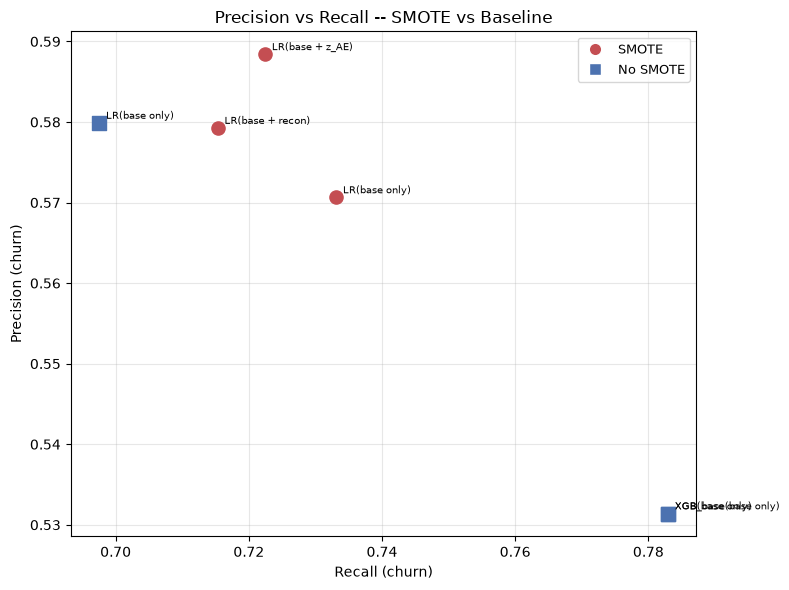

In [61]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(8, 6))
for _, row in combined.iterrows():
    color  = '#c44e52' if row['method'] == 'SMOTE' else '#4c72b0'
    marker = 'o'       if row['method'] == 'SMOTE' else 's'
    ax.scatter(row['recall_churn'], row['precision_churn'],
               color=color, marker=marker, s=90, zorder=3)
    ax.annotate(row['model'], (row['recall_churn'], row['precision_churn']),
                textcoords='offset points', xytext=(5, 3), fontsize=7.5)

ax.legend(handles=[
    Line2D([0],[0], marker='o', color='w', markerfacecolor='#c44e52', markersize=9, label='SMOTE'),
    Line2D([0],[0], marker='s', color='w', markerfacecolor='#4c72b0', markersize=9, label='No SMOTE'),
], fontsize=9)
ax.set_xlabel('Recall (churn)')
ax.set_ylabel('Precision (churn)')
ax.set_title('Precision vs Recall -- SMOTE vs Baseline')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SMOTE_FIG / 'pr_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Summary

In [62]:
best_row = smote_results.sort_values('roc_auc',      ascending=False).iloc[0]
best_f1  = smote_results.sort_values('f1_churn',     ascending=False).iloc[0]
best_rec = smote_results.sort_values('recall_churn', ascending=False).iloc[0]

print('=== Best SMOTE results ===')
print(f'  Best AUC    : {best_row["model"]:<40}  AUC={best_row["roc_auc"]:.4f}')
print(f'  Best F1     : {best_f1["model"]:<40}  F1={best_f1["f1_churn"]:.4f}')
print(f'  Best Recall : {best_rec["model"]:<40}  Recall={best_rec["recall_churn"]:.4f}')

if baseline_path.exists():
    base_best = baseline.sort_values('roc_auc', ascending=False).iloc[0]
    base_f1   = baseline.sort_values('f1_churn', ascending=False).iloc[0]
    print()
    print(f'Baseline best AUC : {base_best["model"]}  AUC={base_best["roc_auc"]:.4f}')
    print(f'Baseline best F1  : {base_f1["model"]}  F1={base_f1["f1_churn"]:.4f}')
    print()
    print(f'  delta AUC (SMOTE - baseline) : {best_row["roc_auc"] - base_best["roc_auc"]:+.4f}')
    print(f'  delta F1  (SMOTE - baseline) : {best_f1["f1_churn"] - base_f1["f1_churn"]:+.4f}')
    print(f'  delta Rec (SMOTE - baseline) : {best_rec["recall_churn"] - baseline.sort_values("recall_churn", ascending=False).iloc[0]["recall_churn"]:+.4f}')

=== Best SMOTE results ===
  Best AUC    : LR(base + z_AE)                           AUC=0.8495
  Best F1     : XGB(base only)                            F1=0.6558
  Best Recall : XGB(base + recon)                         Recall=0.8149

Baseline best AUC : LR(base only)  AUC=0.8494
Baseline best F1  : XGB_reg(base only)  F1=0.6436

  delta AUC (SMOTE - baseline) : +0.0001
  delta F1  (SMOTE - baseline) : +0.0122
  delta Rec (SMOTE - baseline) : -0.0071


## 11. XGB + Optuna + SMOTE

Tune XGBoost hyperparameters with Optuna using the SMOTE-balanced dataset.  
**Key detail:** SMOTE is applied *inside each CV fold* (only to the training fold) so synthetic samples never appear in validation -- this avoids optimistic bias.

The best feature variant from Section 7 is used automatically.

In [63]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS  = 60
N_SPLITS  = 5

# Pick best feature variant from Section 7 results
best_feat = smote_results.sort_values('roc_auc', ascending=False).iloc[0]['features']
print(f'Using feature variant: {best_feat}')
print(f'Dims: {variants["fit"][best_feat].shape[1]}')

Using feature variant: base + z_AE
Dims: 76


In [64]:
from sklearn.model_selection import StratifiedKFold

def suggest_xgb_params(trial):
    return {
        'n_estimators':     trial.suggest_int('n_estimators', 200, 700, step=50),
        'max_depth':        trial.suggest_int('max_depth', 3, 8),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'reg_lambda':       trial.suggest_float('reg_lambda', 0.5, 5.0),
        'reg_alpha':        trial.suggest_float('reg_alpha', 0.0, 2.0),
    }


def objective_xgb_smote(trial):
    params = suggest_xgb_params(trial)
    cv     = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    X      = variants['fit'][best_feat]
    scores = []

    for step, (tr_idx, val_idx) in enumerate(cv.split(X, y_fit)):
        X_tr, X_val = X[tr_idx], X[val_idx]
        y_tr, y_val = y_fit[tr_idx], y_fit[val_idx]

        # SMOTE only on training fold -- never touches validation
        smote = SMOTE(sampling_strategy=SMOTE_RATIO, random_state=SEED)
        X_tr_aug, y_tr_aug = smote.fit_resample(X_tr, y_tr)

        scaler = StandardScaler()
        X_tr_aug = scaler.fit_transform(X_tr_aug)
        X_val_sc = scaler.transform(X_val)

        clf = XGBClassifier(
            **params,
            random_state=SEED, eval_metric='logloss', verbosity=0,
        )
        clf.fit(X_tr_aug, y_tr_aug)

        proba = clf.predict_proba(X_val_sc)[:, 1]
        scores.append(average_precision_score(y_val, proba))

        trial.report(float(np.mean(scores)), step)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(scores))

In [65]:
study_smote = optuna.create_study(
    study_name='xgb_smote_telco',
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=1),
)
study_smote.optimize(objective_xgb_smote, n_trials=N_TRIALS, show_progress_bar=True)

best_xgb_params = dict(study_smote.best_params)
completed = [t for t in study_smote.trials if t.state.name == 'COMPLETE']
pruned    = [t for t in study_smote.trials if t.state.name == 'PRUNED']

print(f'Best CV average precision: {study_smote.best_value:.4f}')
print(f'Trials: {len(completed)} completed, {len(pruned)} pruned')
print('Best hyperparameters:')
for k, v in best_xgb_params.items():
    print(f'  {k}: {v}')

Best trial: 58. Best value: 0.653971: 100%|██████████| 60/60 [05:49<00:00,  5.83s/it]

Best CV average precision: 0.6540
Trials: 27 completed, 33 pruned
Best hyperparameters:
  n_estimators: 500
  max_depth: 3
  learning_rate: 0.015253987032305885
  subsample: 0.7441907685459003
  colsample_bytree: 0.6390488560339762
  min_child_weight: 5
  reg_lambda: 3.1388346675942076
  reg_alpha: 1.0025736430912462


In [66]:
# Final model: SMOTE on full fit set, threshold on real stop set, eval on real test
smote_final    = SMOTE(sampling_strategy=SMOTE_RATIO, random_state=SEED)
X_fit_feat     = variants['fit'][best_feat]
X_aug_f, y_aug_f = smote_final.fit_resample(X_fit_feat, y_fit)

scaler_final   = StandardScaler()
X_aug_sc       = scaler_final.fit_transform(X_aug_f)
X_stop_sc      = scaler_final.transform(variants['stop'][best_feat])
X_test_sc      = scaler_final.transform(variants['test'][best_feat])

xgb_tuned = XGBClassifier(
    **best_xgb_params,
    random_state=SEED, eval_metric='logloss', verbosity=0,
)
xgb_tuned.fit(X_aug_sc, y_aug_f)

threshold_tuned = best_f1_threshold(y_stop, xgb_tuned.predict_proba(X_stop_sc)[:, 1])
result_tuned    = evaluate(
    y_test, xgb_tuned.predict_proba(X_test_sc)[:, 1],
    threshold_tuned, 'XGB_tuned_SMOTE', best_feat,
)

print(f'Threshold: {threshold_tuned:.2f}')
print()
for k in ['roc_auc', 'average_precision', 'f1_churn', 'recall_churn', 'precision_churn']:
    print(f'  {k:<22}: {result_tuned[k]:.4f}')

Threshold: 0.35

  roc_auc               : 0.8511
  average_precision     : 0.6624
  f1_churn              : 0.6431
  recall_churn          : 0.7758
  precision_churn       : 0.5491


## 12. Full comparison -- all approaches

XGB tuned + SMOTE vs best plain SMOTE vs semi-supervised baseline.

=== Full comparison (sorted by F1) ===
                       model               method  roc_auc  average_precision  f1_churn  recall_churn  precision_churn
              XGB(base only)          Plain SMOTE   0.8467             0.6616    0.6558        0.7865           0.5623
            XGB(base + z_AE)          Plain SMOTE   0.8449             0.6636    0.6544        0.6940           0.6190
          XGB_reg(base only)   Exp B — XGB tuning   0.8424             0.6496    0.6436        0.7616           0.5573
XGB_tuned_SMOTE(base + z_AE)    XGB tuned + SMOTE   0.8511             0.6624    0.6431        0.7758           0.5491
               LR(base only) Exp A — best per clf   0.8494             0.6540    0.6333        0.6975           0.5799


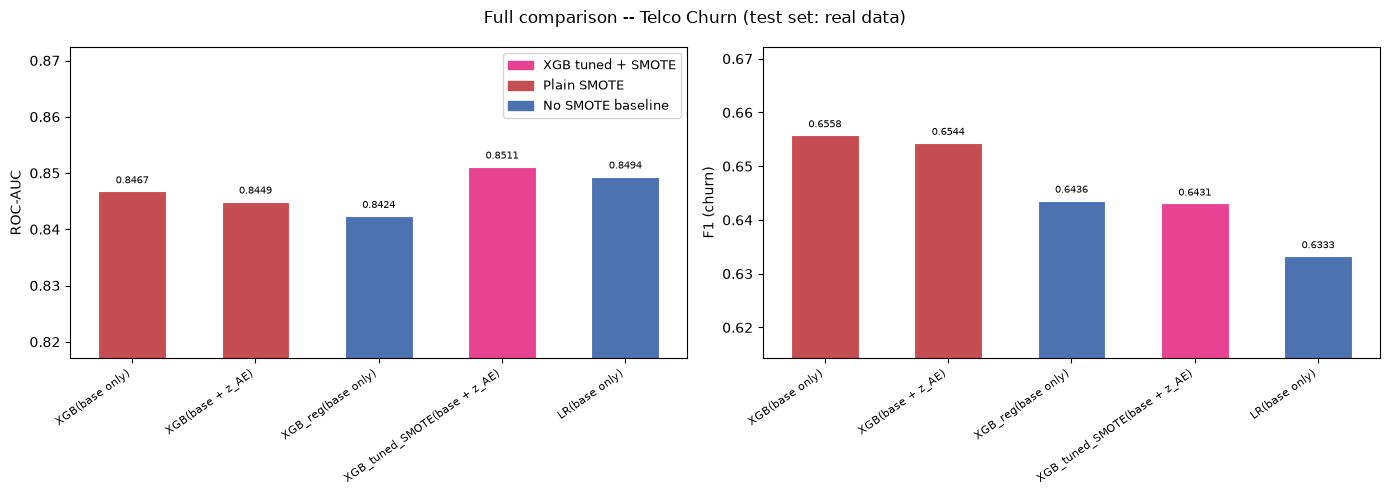

In [67]:
COMPARE_COLS = ['model', 'method', 'roc_auc', 'average_precision',
                'f1_churn', 'recall_churn', 'precision_churn']

tuned_row = pd.DataFrame([{
    'model':             result_tuned['model'],
    'method':            'XGB tuned + SMOTE',
    'roc_auc':           result_tuned['roc_auc'],
    'average_precision': result_tuned['average_precision'],
    'f1_churn':          result_tuned['f1_churn'],
    'recall_churn':      result_tuned['recall_churn'],
    'precision_churn':   result_tuned['precision_churn'],
}])

best_plain_smote = smote_results.sort_values('f1_churn', ascending=False).head(2).copy()
best_plain_smote['method'] = 'Plain SMOTE'

rows_all = [tuned_row[COMPARE_COLS], best_plain_smote[COMPARE_COLS]]

if baseline_path.exists():
    best_base = pd.read_csv(baseline_path).sort_values('f1_churn', ascending=False).head(2).copy()
    rows_all.append(best_base[COMPARE_COLS])

full_comparison = (pd.concat(rows_all, ignore_index=True)
                     .sort_values('f1_churn', ascending=False)
                     .reset_index(drop=True))

full_comparison.to_csv(SMOTE_DIR / 'full_comparison.csv', index=False)
print('=== Full comparison (sorted by F1) ===')
print(full_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Bar chart
from matplotlib.patches import Patch
color_map = {
    'XGB tuned + SMOTE': '#e84393',
    'Plain SMOTE':       '#c44e52',
}
_colors = [color_map.get(m, '#4c72b0') for m in full_comparison['method']]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(full_comparison))
for ax, metric, ylabel in [
    (axes[0], 'roc_auc',  'ROC-AUC'),
    (axes[1], 'f1_churn', 'F1 (churn)'),
]:
    bars = ax.bar(x, full_comparison[metric], color=_colors, width=0.55,
                  edgecolor='white', linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(full_comparison['model'], rotation=35, ha='right', fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_ylim(full_comparison[metric].min() * 0.97, full_comparison[metric].max() * 1.025)
    for bar, val in zip(bars, full_comparison[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
                f'{val:.4f}', ha='center', va='bottom', fontsize=7.5)

axes[0].legend(handles=[
    Patch(color='#e84393', label='XGB tuned + SMOTE'),
    Patch(color='#c44e52', label='Plain SMOTE'),
    Patch(color='#4c72b0', label='No SMOTE baseline'),
], fontsize=9)
plt.suptitle('Full comparison -- Telco Churn (test set: real data)', fontsize=12)
plt.tight_layout()
plt.savefig(SMOTE_FIG / 'full_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Final scorecard: W1 Supervised vs Best Semi-supervised

**6 rows:** top 3 W1 baseline models (seed=42 test) + top 3 semi-supervised experiments (SMOTE / tuned, seed=110 test, same distribution).  
Metrics sorted by **F1** descending. Numbers rounded to 4 decimals.

In [69]:
from IPython.display import display

# ---- W1 baselines (hardcoded, seed=42 test set, 1057 rows) ----------------
# accuracy derived from confusion matrix via recall/precision + known class counts
w1_rows = [
    ("W1 LogReg",        "W1 Supervised", 0.8446, 0.6584, 0.6311, 0.7580, 0.5406, 0.7645),
    ("W1 XGBoost",       "W1 Supervised", 0.8439, 0.6714, 0.6296, 0.7046, 0.5690, 0.7797),
    ("W1 Random Forest", "W1 Supervised", 0.8413, 0.6724, 0.6227, 0.6726, 0.5798, 0.7833),
]

# ---- Best 3 semi-supervised (seed=110 test set) ----------------------------
_parts = [smote_results.copy()]
try:
    _tuned_df = pd.DataFrame([{
        "model":             result_tuned["model"],
        "roc_auc":           result_tuned["roc_auc"],
        "average_precision": result_tuned["average_precision"],
        "f1_churn":          result_tuned["f1_churn"],
        "recall_churn":      result_tuned["recall_churn"],
        "precision_churn":   result_tuned["precision_churn"],
        "TN": result_tuned["TN"], "FP": result_tuned["FP"],
        "FN": result_tuned["FN"], "TP": result_tuned["TP"],
    }])
    _parts.append(_tuned_df)
except NameError:
    print("Tuned XGB not found -- run Section 11 first.")

_all_ss = pd.concat(_parts, ignore_index=True)
_all_ss["accuracy"] = (_all_ss["TN"] + _all_ss["TP"]) / (_all_ss[["TN","FP","FN","TP"]].sum(axis=1))
_top3 = _all_ss.sort_values("f1_churn", ascending=False).head(3)

ss_rows = [
    (row["model"], "Semi-supervised (AE+SMOTE)",
     row["roc_auc"], row["average_precision"],
     row["f1_churn"], row["recall_churn"], row["precision_churn"], row["accuracy"])
    for _, row in _top3.iterrows()
]

# ---- Build 6-row DataFrame -------------------------------------------------
COLS = ["Model", "Source", "ROC-AUC", "Avg Prec", "F1", "Recall", "Precision", "Accuracy"]
scorecard = pd.DataFrame(w1_rows + ss_rows, columns=COLS)
scorecard = scorecard.sort_values("F1", ascending=False).reset_index(drop=True)

# ---- Styled display --------------------------------------------------------
METRIC_COLS = ["ROC-AUC", "Avg Prec", "F1", "Recall", "Precision", "Accuracy"]

def highlight_max(s):
    is_max = s == s.max()
    return ["font-weight: bold; color: #1a7a1a" if v else "" for v in is_max]

styled = (
    scorecard.style
    .format({c: "{:.4f}" for c in METRIC_COLS})
    .apply(highlight_max, subset=METRIC_COLS)
    .set_properties(subset=METRIC_COLS, **{"text-align": "center", "min-width": "72px"})
    .set_properties(subset=["Model"],   **{"text-align": "left",   "min-width": "190px"})
    .set_properties(subset=["Source"],  **{"text-align": "left",   "min-width": "145px"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#080808"),
            ("color", "white"),
            ("font-size", "12px"),
            ("text-align", "center"),
            ("padding", "7px 8px"),
        ]},
        {"selector": "td", "props": [
            ("font-size", "12px"),
            ("padding", "6px 8px"),
            ("border-bottom", "1px solid #dee2e6"),
        ]},
        {"selector": "tr:nth-child(even)", "props": [
            ("background-color", "#0f1011"),
        ]},
        {"selector": "tr:hover", "props": [
            ("background-color", "#000000"),
        ]},
        {"selector": "", "props": [
            ("border-collapse", "collapse"),
            ("width", "100%"),
        ]},
    ])
    .hide(axis="index")
)

print("Note: W1 = seed=42 test | Semi-supervised = seed=110 test  |  Both: 1,057 rows, ~26.6% churn")
print("Best value per metric in bold green.")
print()
display(styled)

scorecard.to_csv(SMOTE_DIR / "final_scorecard.csv", index=False)
print("Saved: final_scorecard.csv")

Note: W1 = seed=42 test | Semi-supervised = seed=110 test  |  Both: 1,057 rows, ~26.6% churn
Best value per metric in bold green.



Model,Source,ROC-AUC,Avg Prec,F1,Recall,Precision,Accuracy
XGB(base only),Semi-supervised (AE+SMOTE),0.8467,0.6616,0.6558,0.7865,0.5623,0.7805
XGB(base + z_AE),Semi-supervised (AE+SMOTE),0.8449,0.6636,0.6544,0.6940,0.6190,0.8051
LR(base + z_AE),Semi-supervised (AE+SMOTE),0.8495,0.6529,0.6486,0.7224,0.5884,0.7919
W1 LogReg,W1 Supervised,0.8446,0.6584,0.6311,0.7580,0.5406,0.7645
W1 XGBoost,W1 Supervised,0.8439,0.6714,0.6296,0.7046,0.5690,0.7797
W1 Random Forest,W1 Supervised,0.8413,0.6724,0.6227,0.6726,0.5798,0.7833


Saved: final_scorecard.csv
